In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-10/PRJDB10426/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,AGE,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,⋯,Organism,Platform,project_name,ReleaseDate,create_date,version,Sample.Name,Sample_name,sex,SRA.Study
,<chr>,<int>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>
1,DRR241928,58,Targeted-Capture,600,127589505,PRJDB10426,SAMD00242470,MIMS.me.human-oral,92643402,HIROSHIMA,⋯,human oral metagenome,ILLUMINA,oral microbiome of orthodontic patients,2022-08-20T00:00:00Z,2022-08-20T12:59:00Z,1,SAMD00242470,29_2,female,DRP008892
2,DRR241936,20,Targeted-Capture,600,214213563,PRJDB10426,SAMD00242478,MIMS.me.human-oral,155919548,HIROSHIMA,⋯,human oral metagenome,ILLUMINA,oral microbiome of orthodontic patients,2022-08-20T00:00:00Z,2022-08-20T13:01:00Z,1,SAMD00242478,32_3,female,DRP008892
3,DRR241953,29,Targeted-Capture,600,82088678,PRJDB10426,SAMD00242387,MIMS.me.human-oral,59949524,HIROSHIMA,⋯,human oral metagenome,ILLUMINA,oral microbiome of orthodontic patients,2022-08-20T00:00:00Z,2022-08-20T13:01:00Z,1,SAMD00242387,38_1,female,DRP008892
4,DRR241954,29,Targeted-Capture,600,106039697,PRJDB10426,SAMD00242388,MIMS.me.human-oral,77201277,HIROSHIMA,⋯,human oral metagenome,ILLUMINA,oral microbiome of orthodontic patients,2022-08-20T00:00:00Z,2022-08-20T13:03:00Z,1,SAMD00242388,38_4,female,DRP008892
5,DRR241955,15,Targeted-Capture,601,71568366,PRJDB10426,SAMD00242389,MIMS.me.human-oral,51647032,HIROSHIMA,⋯,human oral metagenome,ILLUMINA,oral microbiome of orthodontic patients,2022-08-20T00:00:00Z,2022-08-20T12:59:00Z,1,SAMD00242389,40_2_1,female,DRP008892
6,DRR241956,15,Targeted-Capture,600,95881914,PRJDB10426,SAMD00242390,MIMS.me.human-oral,69553606,HIROSHIMA,⋯,human oral metagenome,ILLUMINA,oral microbiome of orthodontic patients,2022-08-20T00:00:00Z,2022-08-20T12:58:00Z,1,SAMD00242390,40_2_2,female,DRP008892


[1] "Run"                            "AGE"                           
 [3] "Assay.Type"                     "AvgSpotLen"                    
 [5] "Bases"                          "BioProject"                    
 [7] "BioSample"                      "BioSampleModel"                
 [9] "Bytes"                          "Center.Name"                   
[11] "Collection_Date"                "Consent"                       
[13] "DATASTORE.filetype"             "DATASTORE.provider"            
[15] "DATASTORE.region"               "env_broad_scale"               
[17] "env_local_scale"                "env_medium"                    
[19] "Experiment"                     "geo_loc_name_country"          
[21] "geo_loc_name_country_continent" "geo_loc_name"                  
[23] "host_disease_stat"              "HOST"                          
[25] "Instrument"                     "lat_lon"                       
[27] "Library.Name"                   "LibraryLayout"                 
[29] "LibrarySelection"               "LibrarySource"                 
[31] "nose_mouth_teeth_throat_disord" "Organism"                      
[33] "Platform"                       "project_name"                  
[35] "ReleaseDate"                    "create_date"                   
[37] "version"                        "Sample.Name"                   
[39] "Sample_name"                    "sex"                           
[41] "SRA.Study"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample_name',
    Age = initial_meta$AGE,
    BMI = NA,
    Sex = initial_meta$sex,
    Region = 'V1-V2',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = initial_meta$env_medium,
    public_time = initial_meta$ReleaseDate,
    PCR_primers = NA,
    title = "The impact of fixed orthodontic appliances on oral microbiome dynamics in Japanese patients",
    Disease_study = "YES",
    Status = NA,
    matched_samples = 'NO')

In [4]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 156
[1] 156


In [5]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<int>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>,<lgl>,<chr>
1,PRJDB10426,DRR241928,29_2,58,NA,female,V1-V2,ILLUMINA,Japan,saliva,2022-08-20T00:00:00Z,NA,The impact of fixed orthodontic appliances on oral microbiome dynamics in Japanese patients,YES,NA,NO
2,PRJDB10426,DRR241936,32_3,20,NA,female,V1-V2,ILLUMINA,Japan,plaque,2022-08-20T00:00:00Z,NA,The impact of fixed orthodontic appliances on oral microbiome dynamics in Japanese patients,YES,NA,NO
3,PRJDB10426,DRR241953,38_1,29,NA,female,V1-V2,ILLUMINA,Japan,plaque,2022-08-20T00:00:00Z,NA,The impact of fixed orthodontic appliances on oral microbiome dynamics in Japanese patients,YES,NA,NO
4,PRJDB10426,DRR241954,38_4,29,NA,female,V1-V2,ILLUMINA,Japan,saliva,2022-08-20T00:00:00Z,NA,The impact of fixed orthodontic appliances on oral microbiome dynamics in Japanese patients,YES,NA,NO
5,PRJDB10426,DRR241955,40_2_1,15,NA,female,V1-V2,ILLUMINA,Japan,plaque,2022-08-20T00:00:00Z,NA,The impact of fixed orthodontic appliances on oral microbiome dynamics in Japanese patients,YES,NA,NO
6,PRJDB10426,DRR241956,40_2_2,15,NA,female,V1-V2,ILLUMINA,Japan,plaque,2022-08-20T00:00:00Z,NA,The impact of fixed orthodontic appliances on oral microbiome dynamics in Japanese patients,YES,NA,NO


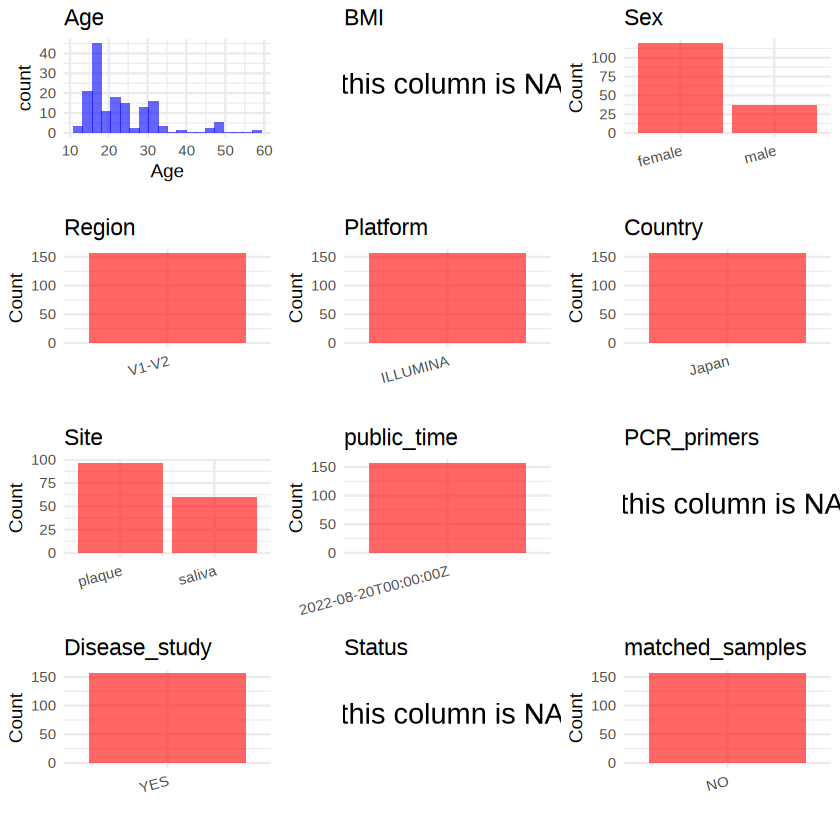

In [6]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [7]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-10/PRJDB10426/metadata.csv", quote = T)